This notebook will explore the data by creating different visualizations.

In [1]:
import pandas as pd

df = pd.read_parquet("../data/processed/combined_english_with_tokens_and_features.parquet")

In [2]:
df.columns

Index(['conversation_id', 'turn', 'user_prompt', 'assistant_response',
       'user_moderation_flag', 'assistant_moderation_flag', 'redacted',
       'prompt_tokens', 'response_tokens', 'turn_tokens', 'history_tokens',
       'previous_response_tokens', 'total_input_tokens', 'prompt_word_count',
       'prompt_char_count', 'avg_word_length', 'question_count',
       'newline_count', 'has_numbers', 'has_url', 'has_code', 'is_explanation',
       'is_summary', 'is_code_request', 'is_creative_writing',
       'is_list_request', 'is_translation', 'is_math', 'requests_brief_answer',
       'requests_detailed_answer'],
      dtype='str')

Get mean and median of token variables

In [5]:
import numpy as np

print(f"Prompt mean: {np.mean(df["prompt_tokens"])}")
print(f"Prompt median: {np.median(df["prompt_tokens"])}")
print(f"Response mean: {np.mean(df["response_tokens"])}")
print(f"Response median: {np.median(df["response_tokens"])}")

Prompt mean: 68.34224688672562
Prompt median: 19.0
Response mean: 229.95999021276978
Response median: 178.0


First, let's examine the distribution of prompt and response tokens.

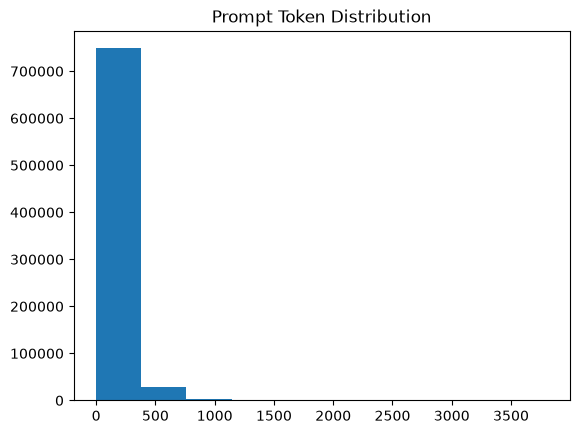

In [13]:
import matplotlib.pyplot as plt

plt.hist(df["prompt_tokens"])
plt.title("Prompt Token Distribution")
plt.show()

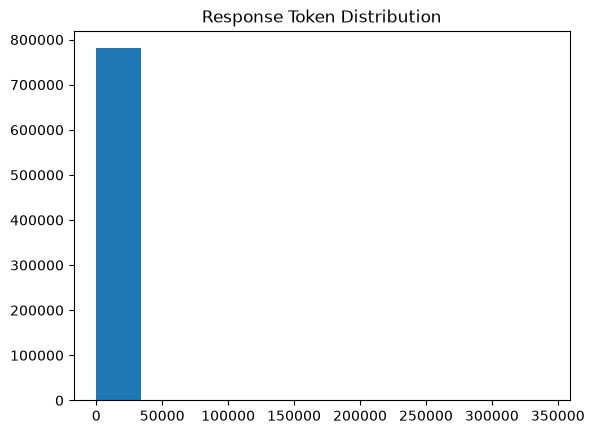

In [14]:
plt.hist(df["response_tokens"])
plt.title("Response Token Distribution")
plt.show()

Both distributions are heavily skewed, making them difficult to model. Let's examine the log transformation of these two variables.

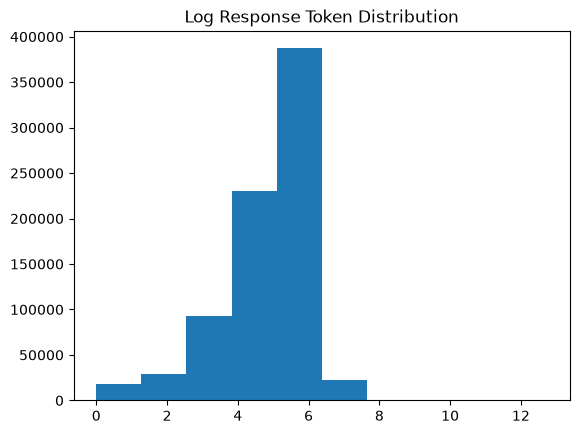

In [15]:
import numpy as np

plt.hist(np.log(df["response_tokens"]))
plt.title("Log Response Token Distribution")
plt.show()

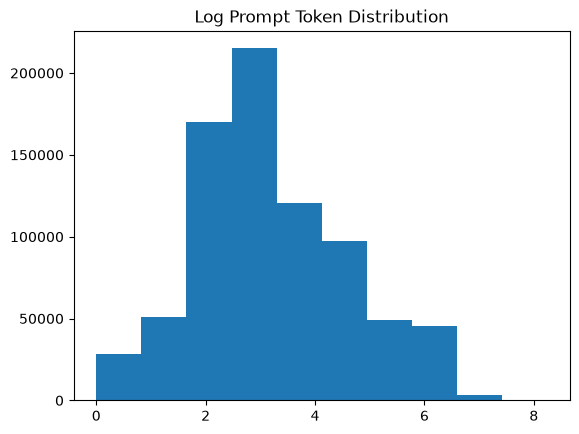

In [16]:
plt.hist(np.log(df["prompt_tokens"]))
plt.title("Log Prompt Token Distribution")
plt.show()

These appear to be much more reasonable distributions for modeling purposes. Let's examine the relationship between both regular prompt and response tokens and log prompt and response tokens with scatterplots.

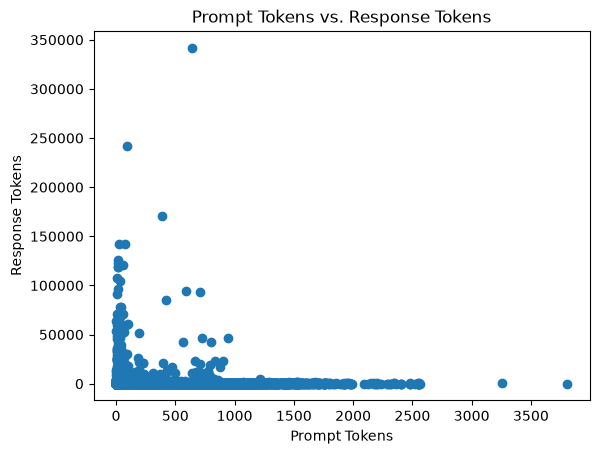

In [ ]:
plt.scatter(df["prompt_tokens"], df["response_tokens"])
plt.title("Prompt Tokens vs. Response Tokens")
plt.xlabel("Prompt Tokens")
plt.ylabel("Response Tokens")
plt.show()

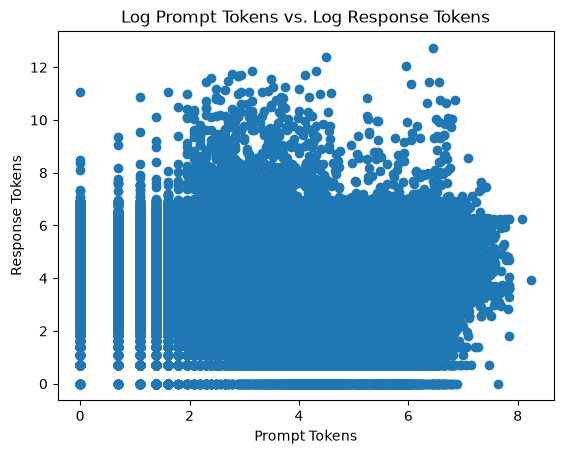

In [17]:
plt.scatter(np.log(df["prompt_tokens"]), np.log(df["response_tokens"]))
plt.title("Log Prompt Tokens vs. Log Response Tokens")
plt.xlabel("Prompt Tokens")
plt.ylabel("Response Tokens")
plt.show()

Interestingly, there does not appear to be an overwhelming pattern here. Let's examine some other variables. Starting with turn.

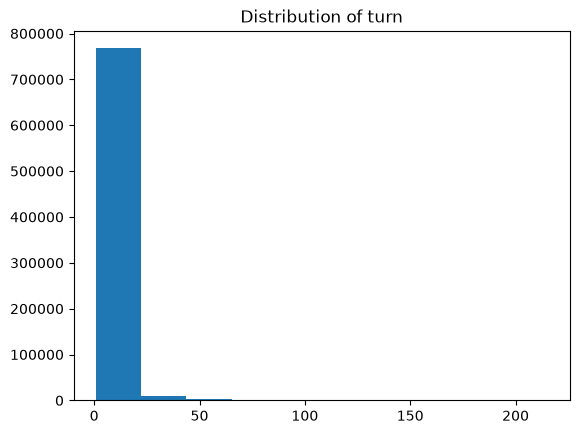

In [18]:
plt.hist(df["turn"])
plt.title("Distribution of turn")
plt.show()

The turn variable is also heavily right skewed. Let's examine the relationship of turn with the response tokens.

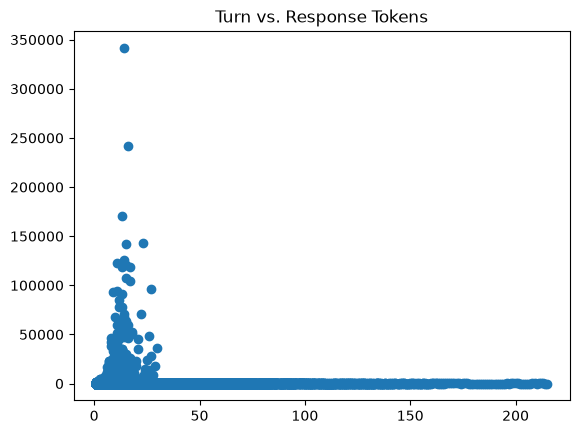

In [23]:
plt.scatter(df["turn"], df["response_tokens"])
plt.title("Turn vs. Response Tokens")
plt.show()

Let's examine the relationship of log(turn) with log(response tokens). 

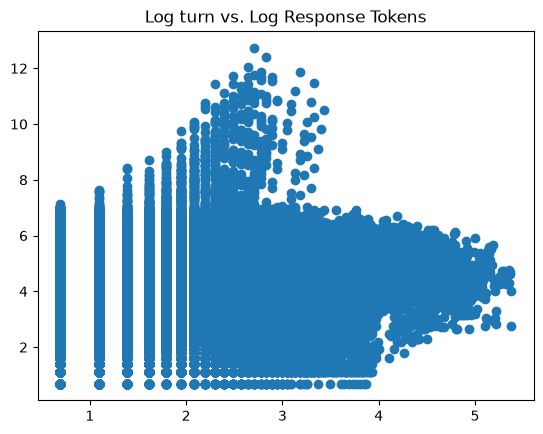

In [24]:
plt.scatter(np.log1p(df["turn"]), np.log1p(df["response_tokens"]))
plt.title("Log turn vs. Log Response Tokens")
plt.show()

Let's examine the history tokens of the conversation.

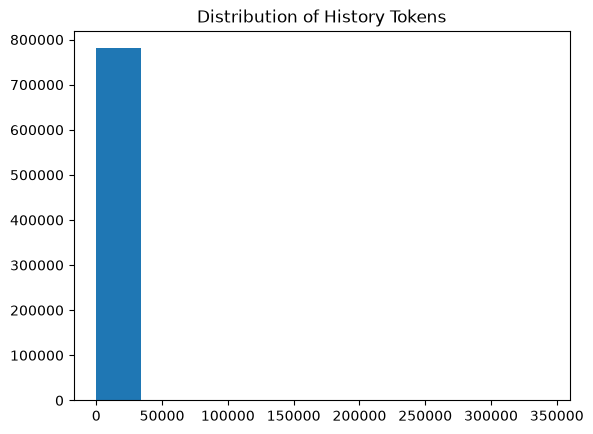

In [25]:
plt.hist(df["history_tokens"])
plt.title("Distribution of History Tokens")
plt.show()

This is also very heavily right-skewed. Let's log transform as well.

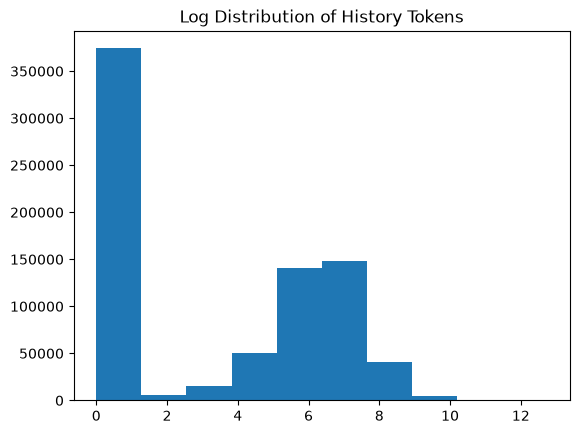

In [26]:
plt.hist(np.log1p(df["history_tokens"]))
plt.title("Log Distribution of History Tokens")
plt.show()

Now this is a bimodal distribution, heavily influenced by the nature of "turn". If turn is 1, this value will be 0. There is a concern that history tokens and turn might be multicollinear. Let's investigate. 

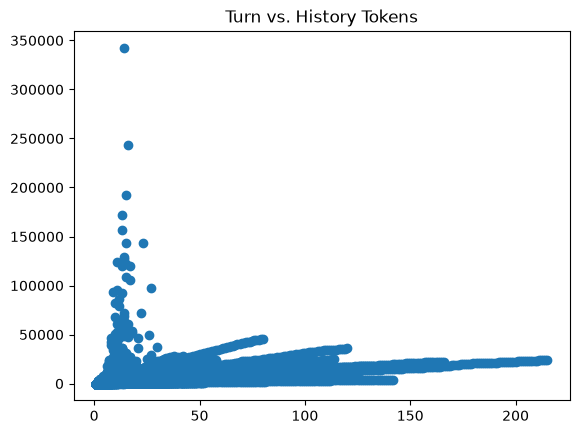

In [27]:
plt.scatter(df["turn"], df["history_tokens"])
plt.title("Turn vs. History Tokens")
plt.show()

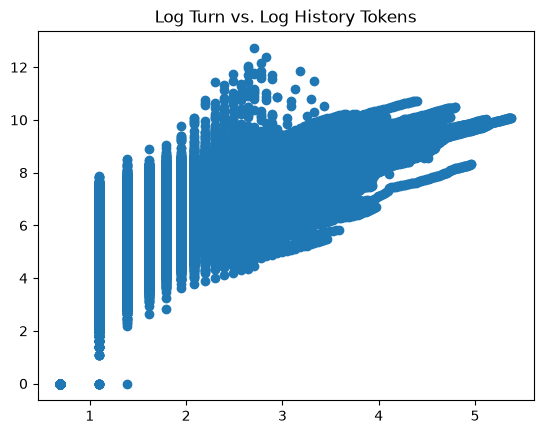

In [29]:
plt.scatter(np.log1p(df["turn"]), np.log1p(df["history_tokens"]))
plt.title("Log Turn vs. Log History Tokens")
plt.show()

In [32]:
np.corrcoef(np.log1p(df["turn"]), np.log1p(df["history_tokens"]))

array([[1.        , 0.84699829],
       [0.84699829, 1.        ]])

There is a lot of correlation between these two features.

Let's investigate the relationship between word count and average word length with response tokens. First, we will examine the distribution of both variables.

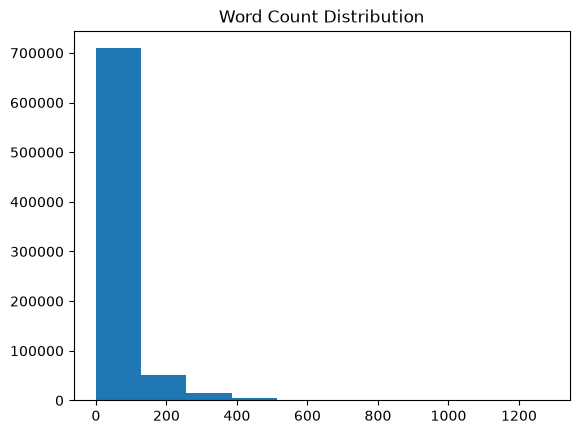

In [34]:
plt.hist(df["prompt_word_count"])
plt.title("Word Count Distribution")
plt.show()

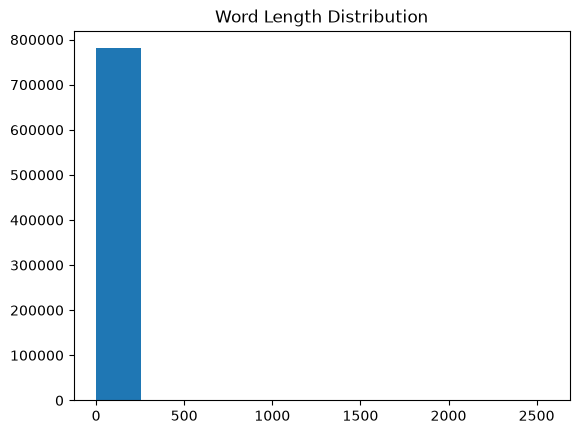

In [35]:
plt.hist(df["avg_word_length"])
plt.title("Word Length Distribution")
plt.show()

Both are heavily right-skewed. Let's log transform both. 

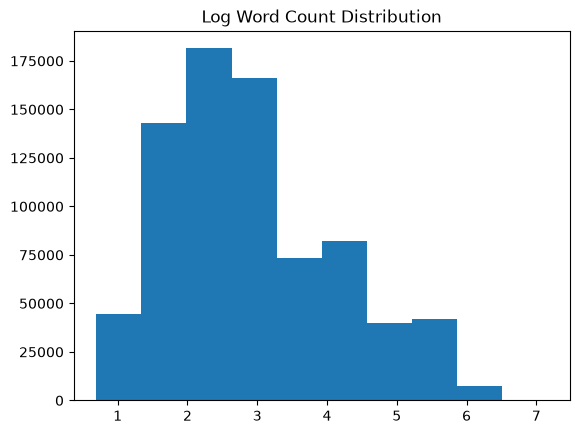

In [36]:
plt.hist(np.log1p(df["prompt_word_count"]))
plt.title("Log Word Count Distribution")
plt.show()

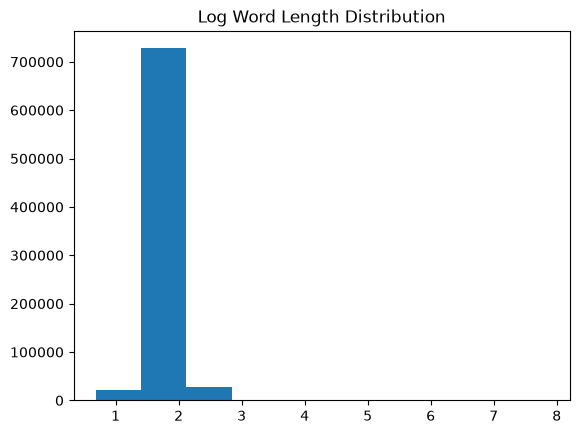

In [37]:
plt.hist(np.log1p(df["avg_word_length"]))
plt.title("Log Word Length Distribution")
plt.show()

Now, let's examine the relationships between both the un-transformed and transformed word variables with the response variable.

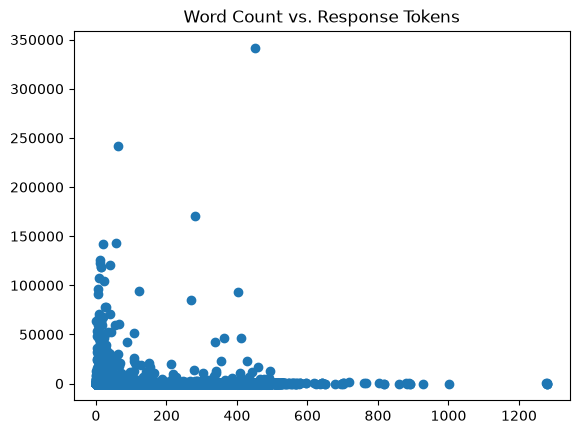

In [38]:
plt.scatter(df["prompt_word_count"], df["response_tokens"])
plt.title("Word Count vs. Response Tokens")
plt.show()

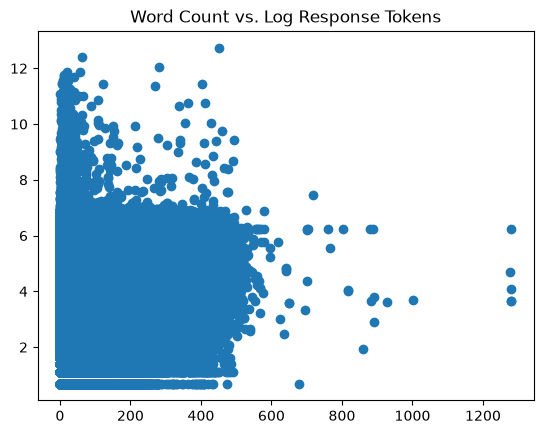

In [40]:
plt.scatter(df["prompt_word_count"], np.log1p(df["response_tokens"]))
plt.title("Word Count vs. Log Response Tokens")
plt.show()

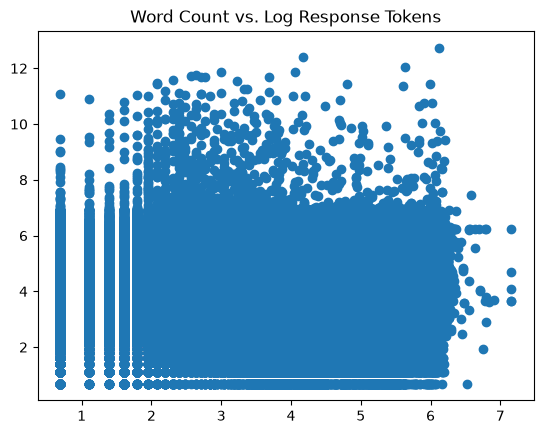

In [41]:
plt.scatter(np.log1p(df["prompt_word_count"]), np.log1p(df["response_tokens"]))
plt.title("Word Count vs. Log Response Tokens")
plt.show()

Let's visualize some of the distributions of the response tokens for different values of indicator variables.

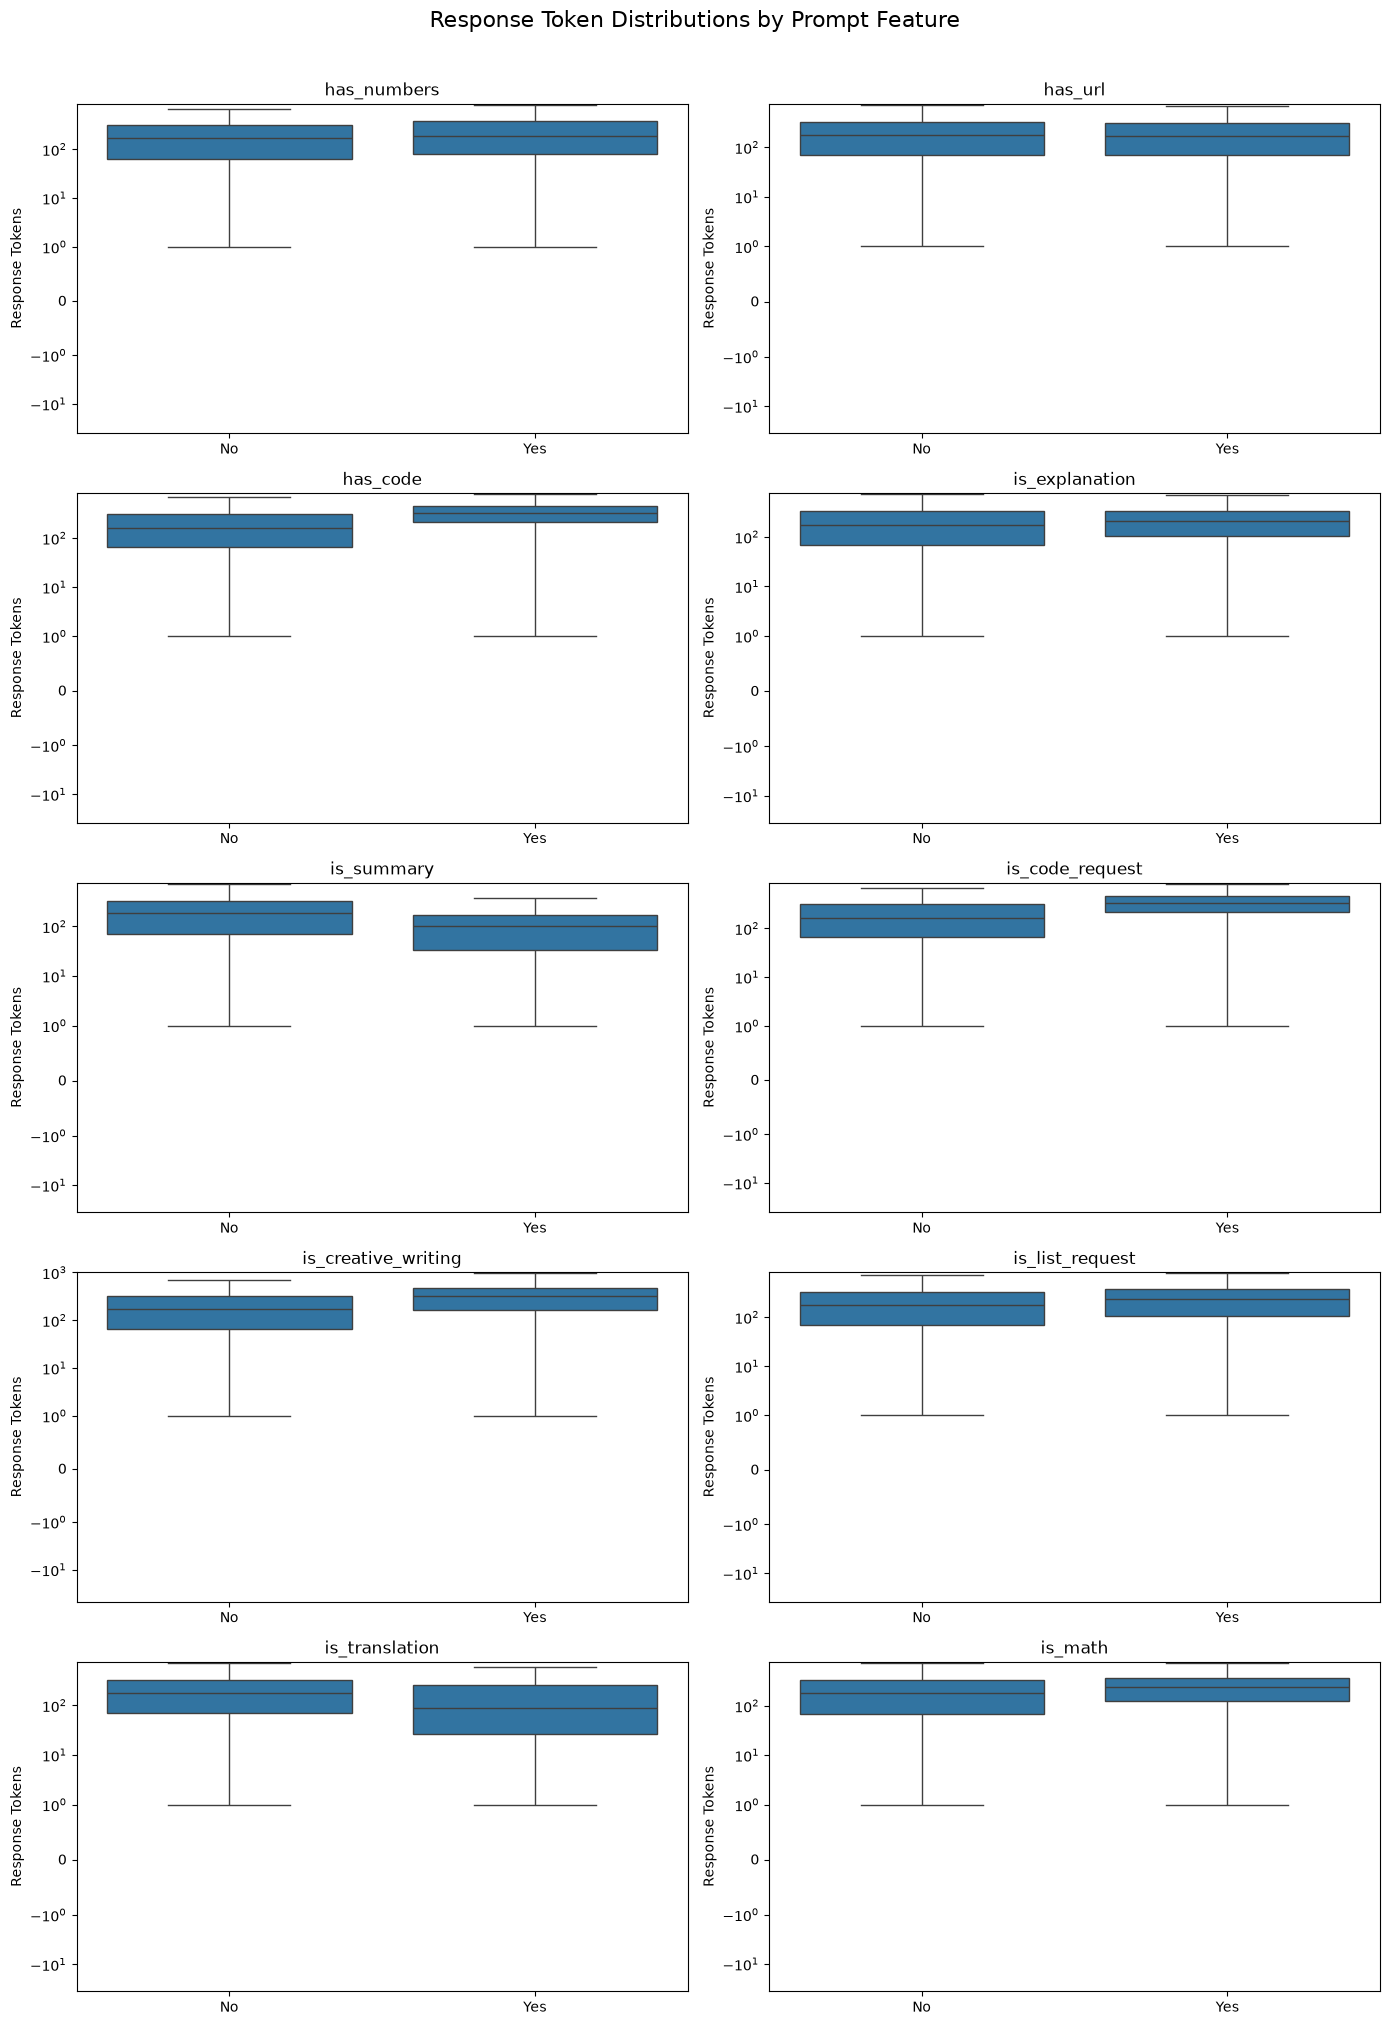

In [ ]:
import seaborn as sns

binary_features = ['has_code', 'is_explanation',
    'is_summary', 'is_code_request', 'is_creative_writing',
    'is_list_request', 'is_translation', 'is_math'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes = axes.flatten()

for i, feature in enumerate(binary_features):
    sns.boxplot(data=df, x=feature, y='response_tokens', order=[0, 1], ax=axes[i], showfliers=False )

    axes[i].set_title(feature)
    axes[i].set_xlabel("")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["No", "Yes"])
    axes[i].set_ylabel("Response Tokens")

    axes[i].set_yscale("symlog", linthresh=1)

plt.suptitle("Response Token Distributions by Prompt Feature", fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

From these boxplots, it does appear that differences in the indicator variables can provide meaningful information on the response tokens. For example, the is_code_request indicates that code-related prompts are met with more response tokens than non-code related prompts.